# Dataset Creation


In [3]:
import re


def clean_text(text):
    """Cleans medical text while preserving numbers, decimals, clinical measurements, and spacing."""
    if not isinstance(text, str):
        return ""

    # Basic normalization
    text = text.lower()

    # Remove URLs, emails
    text = re.sub(r"(?:https?://|www\.)\S+", "", text)
    text = re.sub(r"\b[\w.-]+@[\w.-]+\.\w+\b", "", text)

    phone_patterns = [
        r"\b\(?\d{3}\)?[-.\s]?\d{3}[-.\s]?\d{4}\b",  # (415) 476-5236 or 415-476-5236
        r"\b\d{3}[-.]?\d{3}[-.]?\d{4}\b",  # 4154765236
    ]
    for pattern in phone_patterns:
        text = re.sub(pattern, "", text)

    # Remove fax/tel prefixes and postal codes
    text = re.sub(r"\b(?:tel|fax|telephone):\s*", "", text, flags=re.IGNORECASE)
    text = re.sub(r"\b[A-Z]{2}\s+\d{5}(?:-\d{4})?\b", "", text, flags=re.IGNORECASE)

    # Remove extremely long words
    text = re.sub(r"\b[a-zA-Z]{30,}\b", "", text)

    # Remove extra whitespace and asterisks
    text = re.sub(r"\s+", " ", text)
    text = text.replace("*", "")
    text = text.replace("/", "")

    return text.strip()


## Raw data


In [4]:
import logging
from typing import Dict, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from tqdm import tqdm

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_context("paper", font_scale=1.2)
plt.rcParams["font.family"] = "serif"

COLUMNS_NEEDED = [
    "Patient MRN",
    "Report Text",
    "Accession Number",
    "Exam Completed Date",
    "Patient Sex",
    "Patient Age",
    "Patient Status",
]

CANCER_FILES = [
    "search_astrocytoma_MR_perReport.xlsx",
    "search_Ependymoma_MR_perReport.xlsx",
    "search_Ganglioglioma_MR_perReport.xlsx",
    "search_glioblastoma_MR_perReport.xlsx",
    "search_Gliomatosis_MR_perReport.xlsx",
    "search_Gliosarcoma_MR_perReport.xlsx",
    "search_oligoastrocytoma_MR_perReport.xlsx",
    "search_oligodendroglioma_MR_perReport.xlsx",
    "search_Xanthoastrocytoma_MR_perReport.xlsx",
]


def get_cancer_type(filename: str) -> str:
    """Extract and standardize cancer type from filename."""
    cancer_type = filename.replace("search_", "").split("_")[0]
    return cancer_type.lower()


def load_and_combine_data(base_path: str) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """Load and combine all cancer type data files."""
    mri_dfs = []
    path_dfs = []

    for filename in tqdm(CANCER_FILES, desc="Loading files"):
        try:
            cancer_type = get_cancer_type(filename)

            # Load MRI data
            mri_file = f"{base_path}/{filename}"
            mri_df = pd.read_excel(mri_file, usecols=COLUMNS_NEEDED)
            mri_df["cancer_type"] = cancer_type
            mri_df["clean_text"] = mri_df["Report Text"].apply(clean_text)
            mri_dfs.append(mri_df)

            # Load pathology data
            path_filename = filename.replace("_MR_", "_pathology_")
            path_file = f"{base_path}/{path_filename}"
            path_df = pd.read_excel(path_file, usecols=COLUMNS_NEEDED)
            path_df["cancer_type"] = cancer_type
            path_df["clean_text"] = path_df["Report Text"].apply(clean_text)
            path_dfs.append(path_df)

        except Exception as e:
            logging.error(f"Error loading {filename}: {str(e)}")
            continue

    combined_mri = pd.concat(mri_dfs, ignore_index=True)
    combined_path = pd.concat(path_dfs, ignore_index=True)

    return combined_mri, combined_path


def analyze_demographics(df: pd.DataFrame, dataset_name: str) -> None:
    """Analyze demographics of the dataset."""
    print(f"\n=== Demographics Analysis: {dataset_name} ===")

    # Standardize column names
    df = df.copy()
    df.columns = [col.lower().replace(" ", "_") for col in df.columns]

    # Analyze sex distribution (excluding 'U' category)
    df_filtered = df[df["patient_sex"] != "U"]
    sex_counts = df_filtered["patient_sex"].value_counts()
    sex_percentages = 100 * sex_counts / sex_counts.sum()

    print("\nSex Distribution:")
    for sex, percentage in sex_percentages.items():
        print(f"  {sex}: {percentage:.2f}%")

    # Analyze age distribution
    mean_age = df["patient_age"].mean()
    print(f"\nAge Statistics:")
    print(f"  Mean Age: {mean_age:.2f} years")

    # Analyze patient status
    status_counts = df["patient_status"].value_counts()
    status_percentages = 100 * status_counts / status_counts.sum()

    print("\nPatient Status Distribution:")
    for status, percentage in status_percentages.items():
        print(f"  {status}: {percentage:.2f}%")


def analyze_combined_statistics(
    mri_data: pd.DataFrame, path_data: pd.DataFrame
) -> None:
    """Analyze and print combined statistics from both datasets."""
    # Standardize column names
    mri_data = mri_data.copy()
    path_data = path_data.copy()
    mri_data.columns = [col.lower().replace(" ", "_") for col in mri_data.columns]
    path_data.columns = [col.lower().replace(" ", "_") for col in path_data.columns]

    # Get unique patients from both datasets
    mri_patients = mri_data[
        ["patient_mrn", "patient_sex", "patient_age", "patient_status", "cancer_type"]
    ].drop_duplicates(subset=["patient_mrn"])
    path_patients = path_data[
        ["patient_mrn", "patient_sex", "patient_age", "patient_status", "cancer_type"]
    ].drop_duplicates(subset=["patient_mrn"])

    # Combine unique patients
    all_patients = pd.concat([mri_patients, path_patients]).drop_duplicates(
        subset=["patient_mrn"]
    )

    # Create a summary table for dataset statistics
    print("\n" + "=" * 50)
    print(f"{'Dataset Statistics':^50}")
    print("=" * 50)
    print(f"{'Metric':<25} {'MRI':>10} {'Pathology':>10} {'Combined':>10}")
    print("-" * 50)

    # MRI dataset stats
    mri_unique_patients = len(mri_patients)
    mri_total_reports = len(mri_data)
    mri_reports_per_patient = mri_total_reports / mri_unique_patients

    # Pathology dataset stats
    path_unique_patients = len(path_patients)
    path_total_reports = len(path_data)
    path_reports_per_patient = path_total_reports / path_unique_patients

    # Combined stats
    combined_unique_patients = len(all_patients)
    combined_total_reports = mri_total_reports + path_total_reports
    combined_reports_per_patient = combined_total_reports / combined_unique_patients

    print(
        f"{'Unique patients':<25} {mri_unique_patients:>10,d} {path_unique_patients:>10,d} {combined_unique_patients:>10,d}"
    )
    print(
        f"{'Total reports':<25} {mri_total_reports:>10,d} {path_total_reports:>10,d} {combined_total_reports:>10,d}"
    )
    print(
        f"{'Reports per patient':<25} {mri_reports_per_patient:>10.2f} {path_reports_per_patient:>10.2f} {combined_reports_per_patient:>10.2f}"
    )
    print("-" * 50)

    # Demographics summary for combined dataset
    print("\n" + "=" * 50)
    print(f"{'Combined Dataset Demographics':^50}")
    print("=" * 50)

    # Sex distribution
    all_patients_filtered = all_patients[all_patients["patient_sex"] != "U"]
    sex_counts = all_patients_filtered["patient_sex"].value_counts()
    sex_percentages = 100 * sex_counts / sex_counts.sum()

    print("\nSex Distribution:")
    for sex, percentage in sex_percentages.items():
        print(f"  {sex}: {percentage:.2f}%")

    # Age statistics
    mean_age = all_patients["patient_age"].mean()
    median_age = all_patients["patient_age"].median()
    std_age = all_patients["patient_age"].std()

    print("\nAge Statistics:")
    print(f"  Mean Age: {mean_age:.2f} years")
    print(f"  Median Age: {median_age:.2f} years")
    print(f"  Standard Deviation: {std_age:.2f} years")

    # Patient status
    status_counts = all_patients["patient_status"].value_counts()
    status_percentages = 100 * status_counts / status_counts.sum()

    print("\nPatient Status Distribution:")
    for status, percentage in status_percentages.items():
        print(f"  {status}: {percentage:.2f}%")


print("Loading and cleaning data...")
mri_data, path_data = load_and_combine_data(
    "/data/users/neob/mPower/perReport_12122024"
)

analyze_demographics(mri_data, "MRI Dataset")
analyze_demographics(path_data, "Pathology Dataset")
analyze_combined_statistics(mri_data, path_data)

Loading and cleaning data...


Loading files: 100%|██████████| 9/9 [00:57<00:00,  6.37s/it]


=== Demographics Analysis: MRI Dataset ===

Sex Distribution:
  Male: 56.51%
  Female: 43.49%

Age Statistics:
  Mean Age: 44.09 years

Patient Status Distribution:
  Outpatient: 88.52%
  Inpatient: 10.58%
  Emergency: 0.90%

=== Demographics Analysis: Pathology Dataset ===

Sex Distribution:
  Male: 56.58%
  Female: 43.42%

Age Statistics:
  Mean Age: 47.15 years

Patient Status Distribution:

                Dataset Statistics                
Metric                           MRI  Pathology   Combined
--------------------------------------------------
Unique patients                8,303     12,224     16,149
Total reports                 64,093     26,041     90,134
Reports per patient             7.72       2.13       5.58
--------------------------------------------------

          Combined Dataset Demographics           

Sex Distribution:
  Male: 56.14%
  Female: 43.86%

Age Statistics:
  Mean Age: 45.61 years
  Median Age: 48.00 years
  Standard Deviation: 21.42 years

Patient

## Matching


Matching reports: 100%|██████████| 10633/10633 [00:21<00:00, 489.62it/s]



Total matches found: 97398
Unique patients: 4250
Cancer type distribution:
cancer_type
glioblastoma         38405
astrocytoma          23097
oligodendroglioma    20487
ependymoma            7956
oligoastrocytoma      4089
ganglioglioma         1236
xanthoastrocytoma     1122
gliosarcoma            725
gliomatosis            281
Name: count, dtype: int64


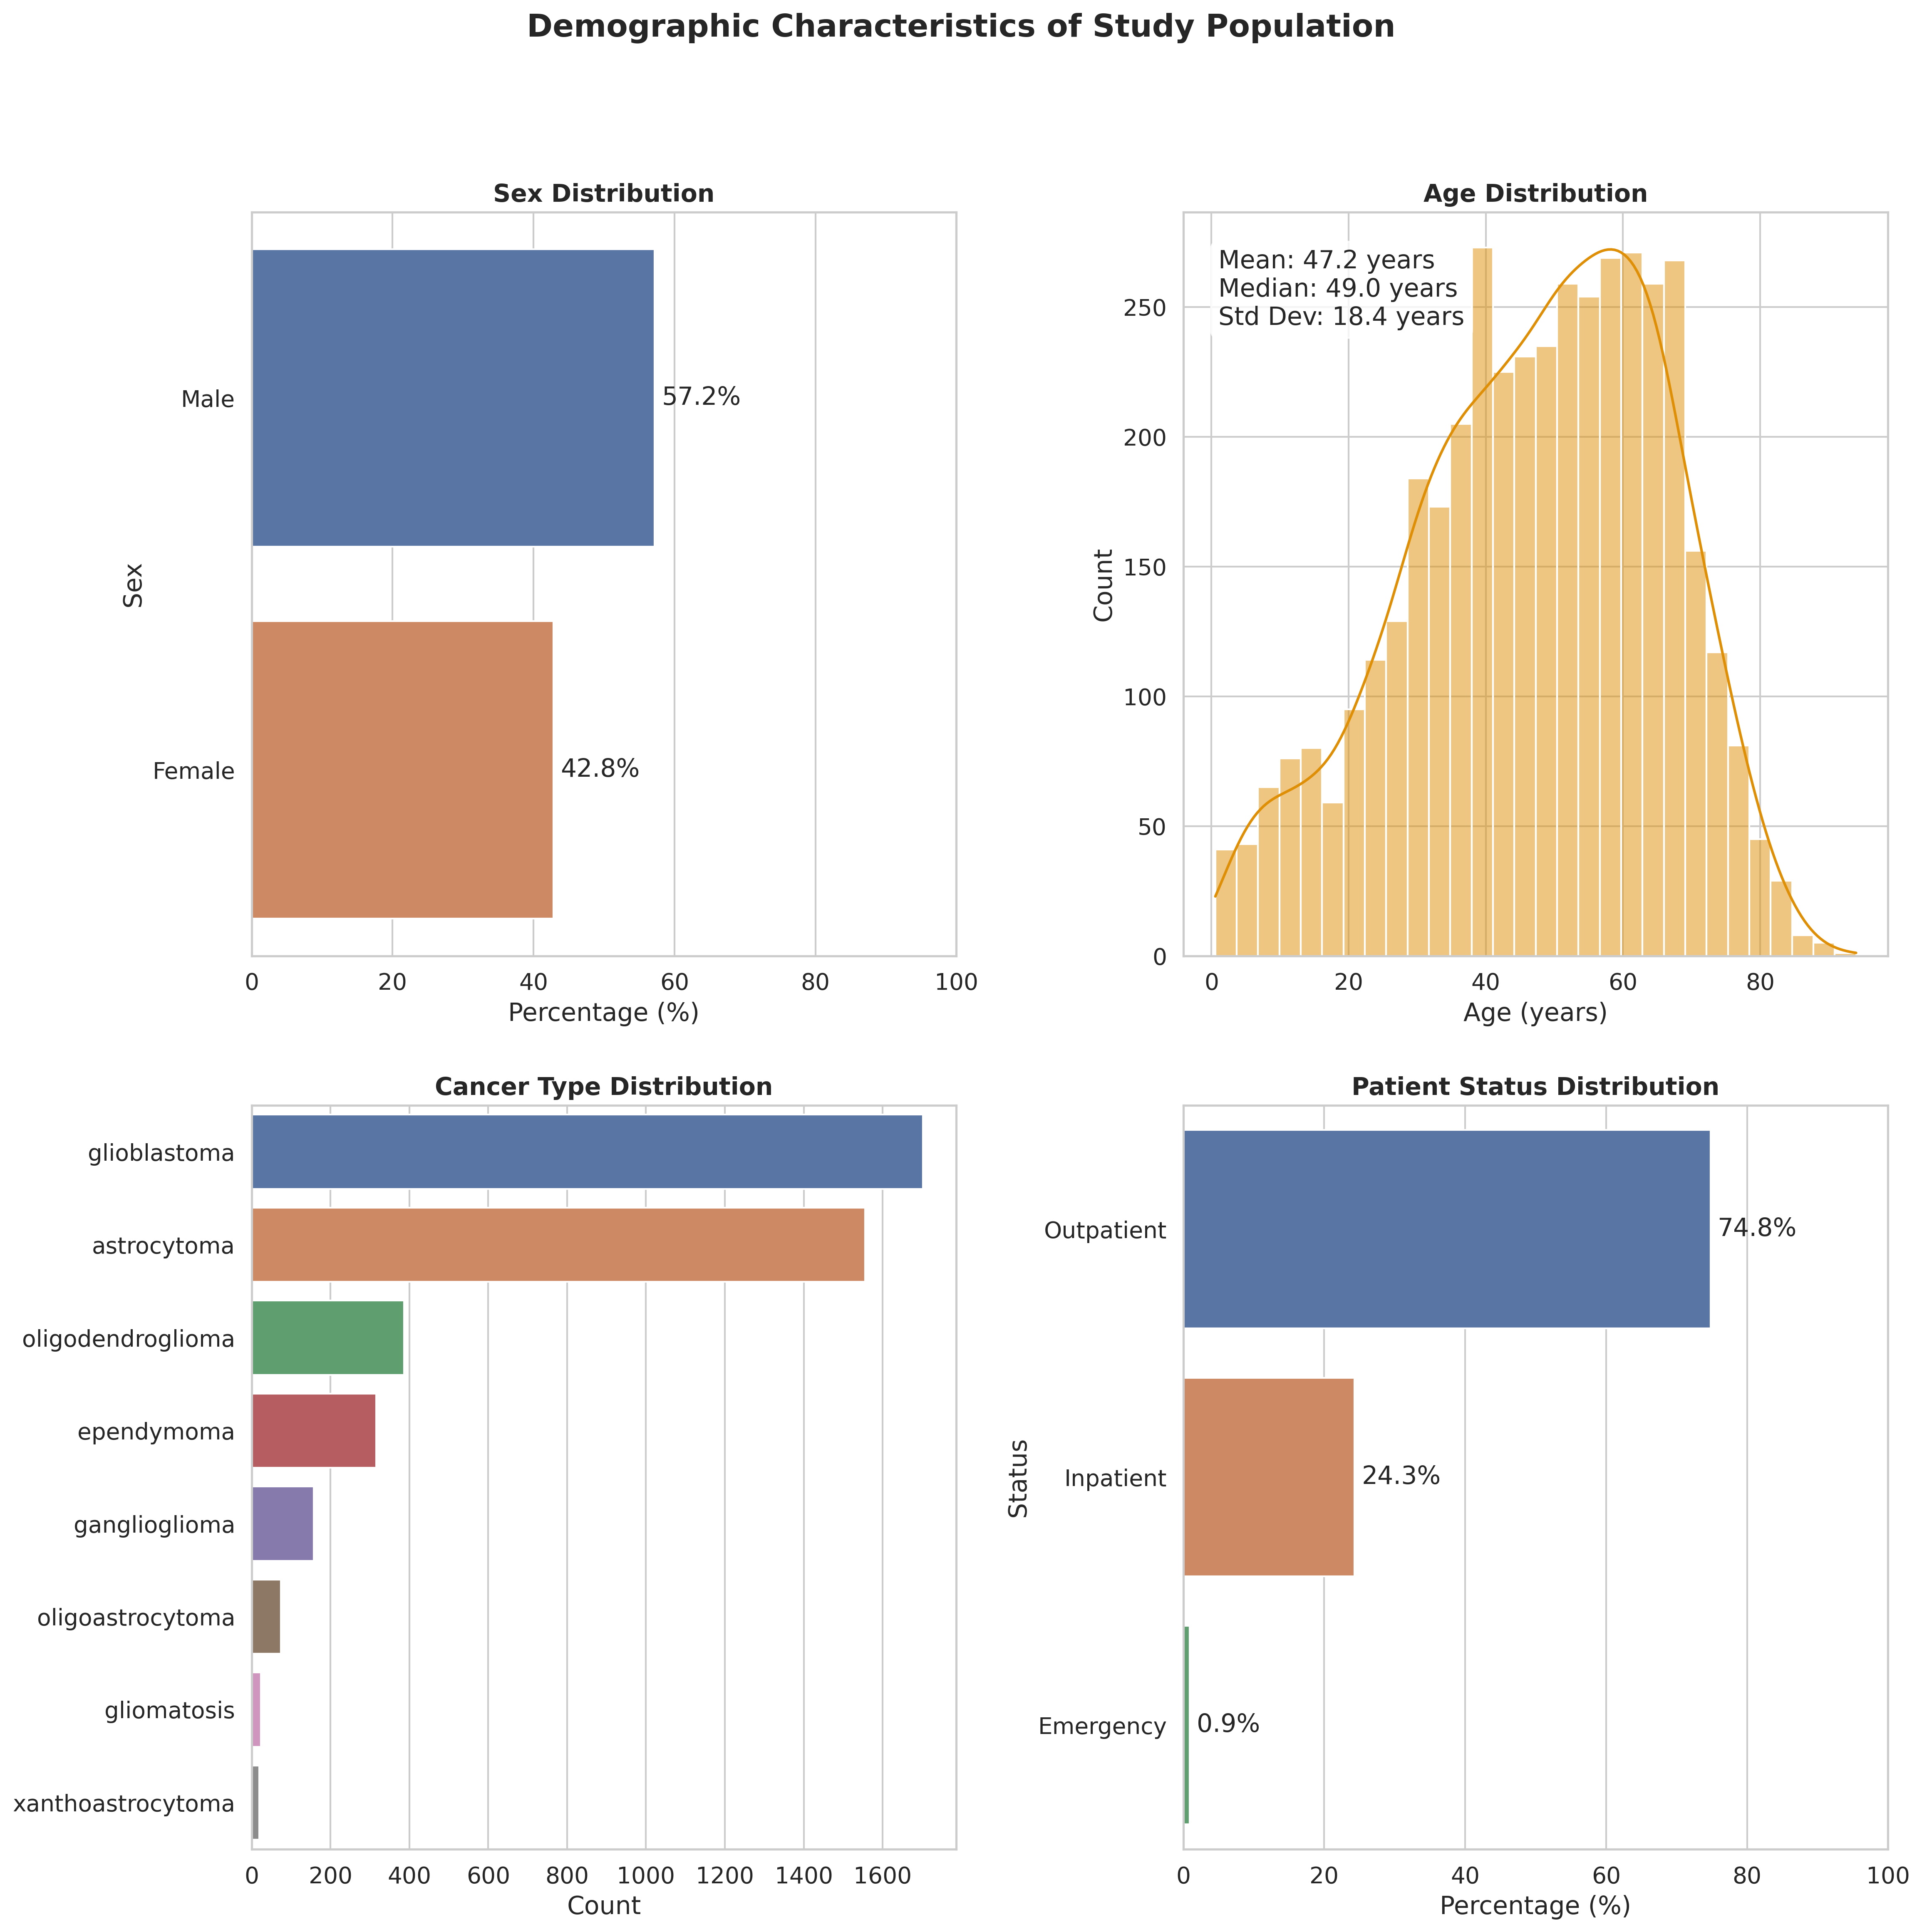

In [18]:
def create_publication_figures(mri_data: pd.DataFrame, path_data: pd.DataFrame) -> None:
    sns.set_theme(style="whitegrid", font_scale=1.2)

    mri_data = mri_data.copy()
    path_data = path_data.copy()
    mri_data.columns = [col.lower().replace(" ", "_") for col in mri_data.columns]
    path_data.columns = [col.lower().replace(" ", "_") for col in path_data.columns]

    mri_patients = mri_data[
        ["patient_mrn", "patient_sex", "patient_age", "patient_status", "cancer_type"]
    ].drop_duplicates(subset=["patient_mrn"])
    path_patients = path_data[
        ["patient_mrn", "patient_sex", "patient_age", "patient_status", "cancer_type"]
    ].drop_duplicates(subset=["patient_mrn"])

    all_patients = pd.concat([mri_patients, path_patients]).drop_duplicates(
        subset=["patient_mrn"]
    )

    fig, axes = plt.subplots(2, 2, figsize=(16, 16), dpi=300)

    palette = sns.color_palette("colorblind")

    ax1 = axes[0, 0]
    sex_counts = all_patients["patient_sex"].value_counts()
    sex_counts = sex_counts[sex_counts > 0]
    sex_percentages = 100 * sex_counts / sex_counts.sum()

    sex_df = pd.DataFrame(
        {"Sex": sex_counts.index, "Percentage": sex_percentages.values}
    )

    bars = sns.barplot(
        x="Percentage", y="Sex", hue="Sex", data=sex_df, ax=ax1, legend=False
    )

    for i, p in enumerate(bars.patches):
        width = p.get_width()
        ax1.text(
            width + 1,
            p.get_y() + p.get_height() / 2,
            f"{width:.1f}%",
            ha="left",
            va="center",
        )

    ax1.set_title("Sex Distribution", fontsize=14, fontweight="bold")
    ax1.set_xlabel("Percentage (%)")
    ax1.set_xlim(0, 100)

    ax2 = axes[0, 1]
    sns.histplot(
        all_patients["patient_age"].dropna(),
        kde=True,
        color=palette[1],
        ax=ax2,
    )
    ax2.set_title("Age Distribution", fontsize=14, fontweight="bold")
    ax2.set_xlabel("Age (years)")
    ax2.set_ylabel("Count")

    age_mean = all_patients["patient_age"].mean()
    age_median = all_patients["patient_age"].median()
    age_std = all_patients["patient_age"].std()
    ax2.text(
        0.05,
        0.95,
        f"Mean: {age_mean:.1f} years\nMedian: {age_median:.1f} years\nStd Dev: {age_std:.1f} years",
        transform=ax2.transAxes,
        verticalalignment="top",
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
    )

    ax3 = axes[1, 0]
    cancer_counts = (
        all_patients["cancer_type"].value_counts().sort_values(ascending=False)
    )
    if len(cancer_counts) > 8:
        cancer_counts = cancer_counts.head(8)

    cancer_df = pd.DataFrame(
        {"Cancer Type": cancer_counts.index, "Count": cancer_counts.values}
    )

    sns.barplot(
        x="Count",
        y="Cancer Type",
        hue="Cancer Type",
        data=cancer_df,
        ax=ax3,
        legend=False,
    )
    ax3.set_title("Cancer Type Distribution", fontsize=14, fontweight="bold")
    ax3.set_xlabel("Count")
    ax3.set_ylabel("")

    ax4 = axes[1, 1]
    status_counts = all_patients["patient_status"].value_counts()
    status_percentages = 100 * status_counts / status_counts.sum()

    status_df = pd.DataFrame(
        {"Status": status_counts.index, "Percentage": status_percentages.values}
    )

    bars = sns.barplot(
        x="Percentage", y="Status", hue="Status", data=status_df, ax=ax4, legend=False
    )

    for i, p in enumerate(bars.patches):
        width = p.get_width()
        ax4.text(
            width + 1,
            p.get_y() + p.get_height() / 2,
            f"{width:.1f}%",
            ha="left",
            va="center",
        )

    ax4.set_title("Patient Status Distribution", fontsize=14, fontweight="bold")
    ax4.set_xlabel("Percentage (%)")
    ax4.set_xlim(0, 100)

    fig.suptitle(
        "Demographic Characteristics of Study Population",
        fontsize=18,
        fontweight="bold",
        y=0.98,
    )

    plt.tight_layout(pad=2.0, rect=[0, 0, 1, 0.96])

    plt.savefig("demographics_publication.pdf", bbox_inches="tight", format="pdf")


def match_clinical_reports(mri_df: pd.DataFrame, path_df: pd.DataFrame) -> pd.DataFrame:
    """Match MRI and pathology reports based on patient and cancer type."""
    matches = []

    mri_df = mri_df.copy()
    path_df = path_df.copy()

    for (mrn, cancer_type), mri_group in tqdm(
        mri_df.groupby(["Patient MRN", "cancer_type"]), desc="Matching reports"
    ):
        path_group = path_df[
            (path_df["Patient MRN"] == mrn) & (path_df["cancer_type"] == cancer_type)
        ]

        if not path_group.empty:
            for _, mri in mri_group.iterrows():
                for _, path in path_group.iterrows():
                    matches.append(
                        {
                            "mrn": mrn,
                            "cancer_type": cancer_type,
                            "mri_accession": mri["Accession Number"],
                            "path_accession": path["Accession Number"],
                            "mri_text": mri["clean_text"],
                            "path_text": path["clean_text"],
                            "mri_date": mri["Exam Completed Date"],
                            "path_date": path["Exam Completed Date"],
                        }
                    )

    matches_df = pd.DataFrame(matches)

    print(f"\nTotal matches found: {len(matches_df)}")
    print(f"Unique patients: {matches_df['mrn'].nunique()}")
    print(f"Cancer type distribution:\n{matches_df['cancer_type'].value_counts()}")

    matched_mri_data = mri_df[mri_df["Patient MRN"].isin(matches_df["mrn"])]
    matched_path_data = path_df[path_df["Patient MRN"].isin(matches_df["mrn"])]

    create_publication_figures(matched_mri_data, matched_path_data)

    return matches_df

    
matches_df = match_clinical_reports(mri_data, path_data)

In [ ]:
## matching with a window of 180 days

#MAX_DAYS_APART = 180  # adjust as needed

#def match_clinical_reports(mri_df: pd.DataFrame, path_df: pd.DataFrame,
#                           max_gap: int = MAX_DAYS_APART) -> pd.DataFrame:
#    matches = []
#    mri_df = mri_df.copy()
#    path_df = path_df.copy()

#    # ensure dates are datetime objects once, up front
#    mri_df["Exam Completed Date"]  = pd.to_datetime(mri_df["Exam Completed Date"],
#                                                    errors="coerce")
#    path_df["Exam Completed Date"] = pd.to_datetime(path_df["Exam Completed Date"],
#                                                    errors="coerce")

#    for (mrn, cancer_type), mri_group in tqdm(
#        mri_df.groupby(["Patient MRN", "cancer_type"]), desc="Matching reports"
#    ):
#        path_group = path_df[
#            (path_df["Patient MRN"] == mrn) & (path_df["cancer_type"] == cancer_type)
#        ]

#        # if no path reports, continue
#        if path_group.empty:
#            continue

#        for _, mri in mri_group.iterrows():
#            # limit to pathology reports within the window
#            close_paths = path_group[
#                (path_group["Exam Completed Date"]
#                 .sub(mri["Exam Completed Date"])
#                 .abs()
#                 .dt.days <= max_gap)
#            ]

#            for _, path in close_paths.iterrows():
#                matches.append(
#                    {
#                        "mrn": mrn,
#                        "cancer_type": cancer_type,
#                        "mri_accession": mri["Accession Number"],
#                        "path_accession": path["Accession Number"],
#                        "mri_text": mri["clean_text"],
#                        "path_text": path["clean_text"],
#                        "mri_date": mri["Exam Completed Date"],
#                        "path_date": path["Exam Completed Date"],
#                    }
#                )

#    return pd.DataFrame(matches)


In [ ]:
def analyze_time_windows(matches_df: pd.DataFrame) -> None:
    """Print baseline stats, gap distribution, and retention by time window."""
    df = matches_df.copy()
    
    df["mri_date"]  = pd.to_datetime(df["mri_date"],  errors="coerce")
    df["path_date"] = pd.to_datetime(df["path_date"], errors="coerce")
    df["gap_days"]  = (df["path_date"] - df["mri_date"]).dt.days
    
    total_pairs   = len(df)
    unique_mrns   = df["mrn"].nunique()
    cancer_types  = df["cancer_type"].nunique()
    
    print("\n=== BASELINE STATISTICS ===")
    print(f"Total matched pairs: {total_pairs:,}")
    print(f"Unique patients   : {unique_mrns:,}")
    print(f"Cancer types      : {cancer_types}\n")
    
    percentiles = [25, 50, 75, 90, 95, 99]
    pct_vals    = np.percentile(df["gap_days"].dropna(), percentiles)
    
    print("=== TIME GAP DISTRIBUTION ===")
    print(f"Mean gap   : {df['gap_days'].mean():.1f} days")
    print(f"Median gap : {df['gap_days'].median():.1f} days")
    for p, val in zip(percentiles, pct_vals):
        print(f"{p:>2}th percentile: {val:.1f} days")
    print(f"Max gap    : {df['gap_days'].max():.1f} days\n")
    
    windows = [7, 14, 30, 60, 90, 120, 180, 365, 730]   # days
    print("=== PAIRS REMAINING BY TIME WINDOW ===")
    print(f"{'Window':>10} | {'Pairs':>10} | {'% of Total':>11} | {'Unique MRNs':>12} | {'% Loss':>7}")
    print("-" * 62)
    for w in windows:
        kept = df[df["gap_days"].abs() <= w]
        pct  = 100.0 * len(kept) / total_pairs
        loss = 100.0 - pct
        print(f"±{w:>3}d | {len(kept):>10,} | {pct:>10.1f}% | {kept['mrn'].nunique():>12,} | {loss:>6.1f}%")
    
    # include the no-limit row for comparison
    print(f"{'No limit':>10} | {total_pairs:>10,} | {100.0:>10.1f}% | {unique_mrns:>12,} | {0.0:>6.1f}%\n")

# run the analysis
analyze_time_windows(matches_df)


=== BASELINE STATISTICS ===
Total matched pairs: 97,398
Unique patients   : 4,250
Cancer types      : 9

=== TIME GAP DISTRIBUTION ===
Mean gap   : -377.3 days
Median gap : -235.0 days
25th percentile: -918.0 days
50th percentile: -235.0 days
75th percentile: 3.0 days
90th percentile: 969.3 days
95th percentile: 2013.0 days
99th percentile: 4231.0 days
Max gap    : 9799.0 days

=== PAIRS REMAINING BY TIME WINDOW ===
    Window |      Pairs |  % of Total |  Unique MRNs |  % Loss
--------------------------------------------------------------
±  7d |      9,418 |        9.7% |        2,730 |   90.3%
± 14d |     10,378 |       10.7% |        2,832 |   89.3%
± 30d |     12,473 |       12.8% |        3,056 |   87.2%
± 60d |     14,933 |       15.3% |        3,262 |   84.7%
± 90d |     17,955 |       18.4% |        3,510 |   81.6%
±120d |     21,190 |       21.8% |        3,760 |   78.2%
±180d |     26,443 |       27.1% |        3,911 |   72.9%
±365d |     40,436 |       41.5% |        4,058

In [22]:
def time_span_report(df: pd.DataFrame, date_col: str, label: str) -> None:
    dates = pd.to_datetime(df[date_col], errors="coerce")
    earliest = dates.min()
    latest   = dates.max()
    span     = (latest - earliest).days
    print(f"{label}:")
    print(f"   Earliest : {earliest.date()}")
    print(f"   Latest   : {latest.date()}")
    print(f"   Span     : {span:,} days\n")

print("\n=== Time span for matched reports ===\n")

time_span_report(matches_df, "mri_date",  "MRI reports (matched)")

time_span_report(matches_df, "path_date", "Pathology reports (matched)")

date_pairs = pd.to_datetime(matches_df["path_date"], errors="coerce") - \
             pd.to_datetime(matches_df["mri_date"],  errors="coerce")
days_between = date_pairs.dt.days.dropna()

print("Time difference between each MRI report and its paired pathology report:")
print(f"   Mean     : {days_between.mean():.1f} days")
print(f"   Median   : {days_between.median():.1f} days")
print(f"   Std Dev  : {days_between.std():.1f} days")
print(f"   Minimum  : {days_between.min():.0f} days")
print(f"   Maximum  : {days_between.max():.0f} days")


=== Time span for matched reports ===

MRI reports (matched):
   Earliest : 1995-01-10
   Latest   : 2024-12-11
   Span     : 10,928 days

Pathology reports (matched):
   Earliest : 2002-10-02
   Latest   : 2024-12-05
   Span     : 8,099 days

Time difference between each MRI report and its paired pathology report:
   Mean     : -377.3 days
   Median   : -235.0 days
   Std Dev  : 1441.8 days
   Minimum  : -6953 days
   Maximum  : 9799 days


## Creating positive pairs


In [21]:
from pathlib import Path


def create_mnrl_pairs(matches_df: pd.DataFrame) -> pd.DataFrame:
    """Vectorized MNRL pair creation"""
    print("Creating MNRL pairs...")

    # Only need anchor-positive pairs for MNRL
    mnrl_pairs = pd.DataFrame(
        {
            "anchor": matches_df["mri_text"].values,
            "positive": matches_df["path_text"].values,
            "mrn": matches_df["mrn"].values,
            "cancer_type": matches_df["cancer_type"].values,
        }
    )

    print(f"Created {len(mnrl_pairs)} MNRL pairs")
    return mnrl_pairs


def create_training_datasets(
    matches_df: str or pd.DataFrame,
    output_base_path: str = "data/processed",
):
    """Create MNRL dataset and split into train/eval"""
    if isinstance(matches_df, str):
        matches_df = pd.read_csv(matches_df)

    Path(output_base_path).mkdir(parents=True, exist_ok=True)
    Path(output_base_path).joinpath("mnrl").mkdir(parents=True, exist_ok=True)

    unique_mrns = matches_df["mrn"].unique()
    np.random.shuffle(unique_mrns)

    # Create train/eval splits (80/20)
    train_idx = int(0.8 * len(unique_mrns))
    train_mrns = unique_mrns[:train_idx]
    eval_mrns = unique_mrns[train_idx:]

    splits = {
        "train": matches_df[matches_df["mrn"].isin(train_mrns)],
        "eval": matches_df[matches_df["mrn"].isin(eval_mrns)],
    }

    # Process each split
    for split_name, split_df in splits.items():
        print(f"Processing {split_name} split...")
        pairs_df = create_mnrl_pairs(split_df)
        output_path = f"{output_base_path}/mnrl/{split_name}.csv"
        pairs_df.to_csv(output_path, index=False)
        print(f"Saved to {output_path}: {len(pairs_df)} pairs")


create_training_datasets(matches_df, output_base_path="training")

Processing train split...
Creating MNRL pairs...
Created 77485 MNRL pairs
Saved to training/mnrl/train.csv: 77485 pairs
Processing eval split...
Creating MNRL pairs...
Created 19913 MNRL pairs
Saved to training/mnrl/eval.csv: 19913 pairs


## Eval data


In [ ]:
import os

os.makedirs("eval", exist_ok=True)

### tumor type


In [ ]:
NOTES_PATH   = "/data/users/neob/multimodal/get_all_notes-log.xlsx"
HIST_PATH    = "/data/users/neob/multimodal/hist_list.xlsx"
MAPPING_PATH = "/data/users/neob/multimodal/accession_num.csv"

def clean_text(text: str) -> str:
    """Put your text-cleaning logic here (strip, lowercase, etc.)."""
    return text

def clean_and_join_data(
    notes_df: pd.DataFrame,
    tnum_df: pd.DataFrame,
    mapping: pd.DataFrame,
) -> pd.DataFrame:
    notes = notes_df[["MRN", "Anon Report Text", "Exam Date/Time"]].rename(
        columns={"Anon Report Text": "report"}
    )
    notes["MRN"] = notes["MRN"].astype(str)
    notes = notes.dropna(subset=["report"])

    # ----- Tumour number (histology) -------------------------------
    tnum_df_clean = tnum_df.dropna(subset=["hist"]).copy()
    tnum_df_clean["tnum"] = tnum_df_clean["tnum"].str.replace("t", "").astype(str)

    # ----- Acc # ↔ MRN mapping -------------------------------------
    mapping_clean = mapping.copy()
    mapping_clean["tnum"] = (
        mapping_clean["tnum"].astype(str).str.replace(".0", "", regex=False)
    )
    mapping_clean["MRN"] = mapping_clean["mrn"].astype(str)

    # combine mapping + tumour-type
    intermediate = (
        mapping_clean.merge(tnum_df_clean, on="tnum", how="inner")
        .rename(columns={"hist": "tumor_type"})
        [["MRN", "tumor_type"]]
    )

    # ----- Merge with notes ----------------------------------------
    df = (
        notes.merge(intermediate, on="MRN", how="left")
        .drop_duplicates()
        .sort_values("MRN")
    )

    # ----- Clean text & tumour-type --------------------------------
    df["report"] = df["report"].apply(clean_text)

    def normalise_tumour(tumor_type: str) -> str:
        if pd.isna(tumor_type):
            return "other"
        t = str(tumor_type)
        if any(s in t for s in ["Glioblastoma", "Giant Cell Glioblastoma", "Gliosarcoma"]):
            return "glioblastoma"
        if any(s in t for s in ["Astrocytoma", "Xanthoastrocytoma"]):
            return "astrocytoma"
        if any(s in t for s in ["Oligodendroglioma", "Oligodendroblastoma"]):
            return "oligodendroglioma"
        if "Oligoastrocytoma" in t:
            return "oligoastrocytoma"
        return "other"

    df["tumor_type"] = df["tumor_type"].apply(normalise_tumour)

    df = df[df["tumor_type"].isin(["glioblastoma", "astrocytoma", "oligodendroglioma"])]

    return df

notes_df = pd.read_excel(NOTES_PATH)
tnum_df  = pd.read_excel(HIST_PATH)
mapping  = pd.read_csv(MAPPING_PATH)

final_df = clean_and_join_data(notes_df, tnum_df, mapping)

tumor_type_to_label = {
    "glioblastoma":      0,
    "astrocytoma":       1,
    "oligodendroglioma": 2,
}
final_df["class_label"] = final_df["tumor_type"].map(tumor_type_to_label)

final_df.to_csv("eval/tumor_type_eval.csv", index=False)

print("Dataset statistics (3-class):")
print(f"  Samples:  {len(final_df)}")
print(f"  Patients: {final_df['MRN'].nunique()}")
print("\nClass distribution:")
print(final_df["tumor_type"].value_counts().to_string())
print("\nReport length:")
print("  Mean  :", round(final_df['report'].str.len().mean(), 0))
print("  Median:", final_df['report'].str.len().median())

Dataset statistics (3-class):
  Samples:  4046
  Patients: 917

Class distribution:
tumor_type
glioblastoma         1815
astrocytoma          1160
oligodendroglioma    1071

Report length:
  Mean  : 1929.0
  Median: 1863.0


In [ ]:
NOTES_PATH   = "/data/users/neob/multimodal/get_all_notes-log.xlsx"
HIST_PATH    = "/data/users/neob/multimodal/hist_list.xlsx"
MAPPING_PATH = "/data/users/neob/multimodal/accession_num.csv"

def clean_text(text: str) -> str:
    """Put your text-cleaning logic here (strip, lowercase, etc.)."""
    return text

def clean_and_join_data(
    notes_df: pd.DataFrame,
    tnum_df: pd.DataFrame,
    mapping: pd.DataFrame,
) -> pd.DataFrame:
    notes = notes_df[["MRN", "Anon Report Text", "Exam Date/Time"]].rename(
        columns={"Anon Report Text": "report"}
    )
    notes["MRN"] = notes["MRN"].astype(str)
    notes = notes.dropna(subset=["report"])

    # ----- Tumour number (histology) -------------------------------
    tnum_df_clean = tnum_df.dropna(subset=["hist"]).copy()
    tnum_df_clean["tnum"] = tnum_df_clean["tnum"].str.replace("t", "").astype(str)

    # ----- Acc # ↔ MRN mapping -------------------------------------
    mapping_clean = mapping.copy()
    mapping_clean["tnum"] = (
        mapping_clean["tnum"].astype(str).str.replace(".0", "", regex=False)
    )
    mapping_clean["MRN"] = mapping_clean["mrn"].astype(str)

    # combine mapping + tumour-type
    intermediate = (
        mapping_clean.merge(tnum_df_clean, on="tnum", how="inner")
        .rename(columns={"hist": "tumor_type"})
        [["MRN", "tumor_type"]]
    )

    # ----- Merge with notes ----------------------------------------
    df = (
        notes.merge(intermediate, on="MRN", how="left")
        .drop_duplicates()
        .sort_values("MRN")
    )

    # ----- Clean text & tumour-type --------------------------------
    df["report"] = df["report"].apply(clean_text)

    def normalise_tumour(tumor_type: str) -> str:
        if pd.isna(tumor_type):
            return "other"
        t = str(tumor_type)
        if any(s in t for s in ["Glioblastoma", "Giant Cell Glioblastoma", "Gliosarcoma"]):
            return "glioblastoma"
        if any(s in t for s in ["Astrocytoma", "Xanthoastrocytoma"]):
            return "astrocytoma"
        if any(s in t for s in ["Oligodendroglioma", "Oligodendroblastoma"]):
            return "oligodendroglioma"
        if "Oligoastrocytoma" in t:
            return "oligoastrocytoma"
        return "other"

    df["tumor_type"] = df["tumor_type"].apply(normalise_tumour)

    df = df[df["tumor_type"].isin(["glioblastoma", "astrocytoma", "oligodendroglioma"])]

    return df

notes_df = pd.read_excel(NOTES_PATH)
tnum_df  = pd.read_excel(HIST_PATH)
mapping  = pd.read_csv(MAPPING_PATH)

final_df = clean_and_join_data(notes_df, tnum_df, mapping)

tumor_type_to_label = {
    "glioblastoma":      0,
    "astrocytoma":       1,
    "oligodendroglioma": 2,
}
final_df["class_label"] = final_df["tumor_type"].map(tumor_type_to_label)

final_df.to_csv("eval/tumor_type_eval.csv", index=False)

print("Dataset statistics (3-class):")
print(f"  Samples:  {len(final_df)}")
print(f"  Patients: {final_df['MRN'].nunique()}")
print("\nClass distribution:")
print(final_df["tumor_type"].value_counts().to_string())
print("\nReport length:")
print("  Mean  :", round(final_df['report'].str.len().mean(), 0))
print("  Median:", final_df['report'].str.len().median())

Dataset statistics (3-class):
  Samples:  4046
  Patients: 917

Class distribution:
tumor_type
glioblastoma         1815
astrocytoma          1160
oligodendroglioma    1071

Report length:
  Mean  : 1929.0
  Median: 1863.0


In [ ]:
NOTES_PATH   = "/data/users/neob/multimodal/get_all_notes-log.xlsx"
HIST_PATH    = "/data/users/neob/multimodal/hist_list.xlsx"
MAPPING_PATH = "/data/users/neob/multimodal/accession_num.csv"

def clean_text(text: str) -> str:
    """Put your text-cleaning logic here (strip, lowercase, etc.)."""
    return text

def clean_and_join_data(
    notes_df: pd.DataFrame,
    tnum_df: pd.DataFrame,
    mapping: pd.DataFrame,
) -> pd.DataFrame:
    notes = notes_df[["MRN", "Anon Report Text", "Exam Date/Time"]].rename(
        columns={"Anon Report Text": "report"}
    )
    notes["MRN"] = notes["MRN"].astype(str)
    notes = notes.dropna(subset=["report"])

    # ----- Tumour number (histology) -------------------------------
    tnum_df_clean = tnum_df.dropna(subset=["hist"]).copy()
    tnum_df_clean["tnum"] = tnum_df_clean["tnum"].str.replace("t", "").astype(str)

    # ----- Acc # ↔ MRN mapping -------------------------------------
    mapping_clean = mapping.copy()
    mapping_clean["tnum"] = (
        mapping_clean["tnum"].astype(str).str.replace(".0", "", regex=False)
    )
    mapping_clean["MRN"] = mapping_clean["mrn"].astype(str)

    # combine mapping + tumour-type
    intermediate = (
        mapping_clean.merge(tnum_df_clean, on="tnum", how="inner")
        .rename(columns={"hist": "tumor_type"})
        [["MRN", "tumor_type"]]
    )

    # ----- Merge with notes ----------------------------------------
    df = (
        notes.merge(intermediate, on="MRN", how="left")
        .drop_duplicates()
        .sort_values("MRN")
    )

    # ----- Clean text & tumour-type --------------------------------
    df["report"] = df["report"].apply(clean_text)

    def normalise_tumour(tumor_type: str) -> str:
        if pd.isna(tumor_type):
            return "other"
        t = str(tumor_type)
        if any(s in t for s in ["Glioblastoma", "Giant Cell Glioblastoma", "Gliosarcoma"]):
            return "glioblastoma"
        if any(s in t for s in ["Astrocytoma", "Xanthoastrocytoma"]):
            return "astrocytoma"
        if any(s in t for s in ["Oligodendroglioma", "Oligodendroblastoma"]):
            return "oligodendroglioma"
        if "Oligoastrocytoma" in t:
            return "oligoastrocytoma"
        return "other"

    df["tumor_type"] = df["tumor_type"].apply(normalise_tumour)

    df = df[df["tumor_type"].isin(["glioblastoma", "astrocytoma", "oligodendroglioma"])]

    return df

notes_df = pd.read_excel(NOTES_PATH)
tnum_df  = pd.read_excel(HIST_PATH)
mapping  = pd.read_csv(MAPPING_PATH)

final_df = clean_and_join_data(notes_df, tnum_df, mapping)

tumor_type_to_label = {
    "glioblastoma":      0,
    "astrocytoma":       1,
    "oligodendroglioma": 2,
}
final_df["class_label"] = final_df["tumor_type"].map(tumor_type_to_label)

final_df.to_csv("eval/tumor_type_eval.csv", index=False)

print("Dataset statistics (3-class):")
print(f"  Samples:  {len(final_df)}")
print(f"  Patients: {final_df['MRN'].nunique()}")
print("\nClass distribution:")
print(final_df["tumor_type"].value_counts().to_string())
print("\nReport length:")
print("  Mean  :", round(final_df['report'].str.len().mean(), 0))
print("  Median:", final_df['report'].str.len().median())

Dataset statistics (3-class):
  Samples:  4046
  Patients: 917

Class distribution:
tumor_type
glioblastoma         1815
astrocytoma          1160
oligodendroglioma    1071

Report length:
  Mean  : 1929.0
  Median: 1863.0


In [ ]:
NOTES_PATH   = "/data/users/neob/multimodal/get_all_notes-log.xlsx"
HIST_PATH    = "/data/users/neob/multimodal/hist_list.xlsx"
MAPPING_PATH = "/data/users/neob/multimodal/accession_num.csv"

def clean_text(text: str) -> str:
    """Put your text-cleaning logic here (strip, lowercase, etc.)."""
    return text

def clean_and_join_data(
    notes_df: pd.DataFrame,
    tnum_df: pd.DataFrame,
    mapping: pd.DataFrame,
) -> pd.DataFrame:
    notes = notes_df[["MRN", "Anon Report Text", "Exam Date/Time"]].rename(
        columns={"Anon Report Text": "report"}
    )
    notes["MRN"] = notes["MRN"].astype(str)
    notes = notes.dropna(subset=["report"])

    # ----- Tumour number (histology) -------------------------------
    tnum_df_clean = tnum_df.dropna(subset=["hist"]).copy()
    tnum_df_clean["tnum"] = tnum_df_clean["tnum"].str.replace("t", "").astype(str)

    # ----- Acc # ↔ MRN mapping -------------------------------------
    mapping_clean = mapping.copy()
    mapping_clean["tnum"] = (
        mapping_clean["tnum"].astype(str).str.replace(".0", "", regex=False)
    )
    mapping_clean["MRN"] = mapping_clean["mrn"].astype(str)

    # combine mapping + tumour-type
    intermediate = (
        mapping_clean.merge(tnum_df_clean, on="tnum", how="inner")
        .rename(columns={"hist": "tumor_type"})
        [["MRN", "tumor_type"]]
    )

    # ----- Merge with notes ----------------------------------------
    df = (
        notes.merge(intermediate, on="MRN", how="left")
        .drop_duplicates()
        .sort_values("MRN")
    )

    # ----- Clean text & tumour-type --------------------------------
    df["report"] = df["report"].apply(clean_text)

    def normalise_tumour(tumor_type: str) -> str:
        if pd.isna(tumor_type):
            return "other"
        t = str(tumor_type)
        if any(s in t for s in ["Glioblastoma", "Giant Cell Glioblastoma", "Gliosarcoma"]):
            return "glioblastoma"
        if any(s in t for s in ["Astrocytoma", "Xanthoastrocytoma"]):
            return "astrocytoma"
        if any(s in t for s in ["Oligodendroglioma", "Oligodendroblastoma"]):
            return "oligodendroglioma"
        if "Oligoastrocytoma" in t:
            return "oligoastrocytoma"
        return "other"

    df["tumor_type"] = df["tumor_type"].apply(normalise_tumour)

    df = df[df["tumor_type"].isin(["glioblastoma", "astrocytoma", "oligodendroglioma"])]

    return df

notes_df = pd.read_excel(NOTES_PATH)
tnum_df  = pd.read_excel(HIST_PATH)
mapping  = pd.read_csv(MAPPING_PATH)

final_df = clean_and_join_data(notes_df, tnum_df, mapping)

tumor_type_to_label = {
    "glioblastoma":      0,
    "astrocytoma":       1,
    "oligodendroglioma": 2,
}
final_df["class_label"] = final_df["tumor_type"].map(tumor_type_to_label)

final_df.to_csv("eval/tumor_type_eval.csv", index=False)

print("Dataset statistics (3-class):")
print(f"  Samples:  {len(final_df)}")
print(f"  Patients: {final_df['MRN'].nunique()}")
print("\nClass distribution:")
print(final_df["tumor_type"].value_counts().to_string())
print("\nReport length:")
print("  Mean  :", round(final_df['report'].str.len().mean(), 0))
print("  Median:", final_df['report'].str.len().median())

Dataset statistics (3-class):
  Samples:  4046
  Patients: 917

Class distribution:
tumor_type
glioblastoma         1815
astrocytoma          1160
oligodendroglioma    1071

Report length:
  Mean  : 1929.0
  Median: 1863.0


In [ ]:
NOTES_PATH   = "/data/users/neob/multimodal/get_all_notes-log.xlsx"
HIST_PATH    = "/data/users/neob/multimodal/hist_list.xlsx"
MAPPING_PATH = "/data/users/neob/multimodal/accession_num.csv"

def clean_text(text: str) -> str:
    """Put your text-cleaning logic here (strip, lowercase, etc.)."""
    return text

def clean_and_join_data(
    notes_df: pd.DataFrame,
    tnum_df: pd.DataFrame,
    mapping: pd.DataFrame,
) -> pd.DataFrame:
    notes = notes_df[["MRN", "Anon Report Text", "Exam Date/Time"]].rename(
        columns={"Anon Report Text": "report"}
    )
    notes["MRN"] = notes["MRN"].astype(str)
    notes = notes.dropna(subset=["report"])

    # ----- Tumour number (histology) -------------------------------
    tnum_df_clean = tnum_df.dropna(subset=["hist"]).copy()
    tnum_df_clean["tnum"] = tnum_df_clean["tnum"].str.replace("t", "").astype(str)

    # ----- Acc # ↔ MRN mapping -------------------------------------
    mapping_clean = mapping.copy()
    mapping_clean["tnum"] = (
        mapping_clean["tnum"].astype(str).str.replace(".0", "", regex=False)
    )
    mapping_clean["MRN"] = mapping_clean["mrn"].astype(str)

    # combine mapping + tumour-type
    intermediate = (
        mapping_clean.merge(tnum_df_clean, on="tnum", how="inner")
        .rename(columns={"hist": "tumor_type"})
        [["MRN", "tumor_type"]]
    )

    # ----- Merge with notes ----------------------------------------
    df = (
        notes.merge(intermediate, on="MRN", how="left")
        .drop_duplicates()
        .sort_values("MRN")
    )

    # ----- Clean text & tumour-type --------------------------------
    df["report"] = df["report"].apply(clean_text)

    def normalise_tumour(tumor_type: str) -> str:
        if pd.isna(tumor_type):
            return "other"
        t = str(tumor_type)
        if any(s in t for s in ["Glioblastoma", "Giant Cell Glioblastoma", "Gliosarcoma"]):
            return "glioblastoma"
        if any(s in t for s in ["Astrocytoma", "Xanthoastrocytoma"]):
            return "astrocytoma"
        if any(s in t for s in ["Oligodendroglioma", "Oligodendroblastoma"]):
            return "oligodendroglioma"
        if "Oligoastrocytoma" in t:
            return "oligoastrocytoma"
        return "other"

    df["tumor_type"] = df["tumor_type"].apply(normalise_tumour)

    df = df[df["tumor_type"].isin(["glioblastoma", "astrocytoma", "oligodendroglioma"])]

    return df

notes_df = pd.read_excel(NOTES_PATH)
tnum_df  = pd.read_excel(HIST_PATH)
mapping  = pd.read_csv(MAPPING_PATH)

final_df = clean_and_join_data(notes_df, tnum_df, mapping)

tumor_type_to_label = {
    "glioblastoma":      0,
    "astrocytoma":       1,
    "oligodendroglioma": 2,
}
final_df["class_label"] = final_df["tumor_type"].map(tumor_type_to_label)

final_df.to_csv("eval/tumor_type_eval.csv", index=False)

print("Dataset statistics (3-class):")
print(f"  Samples:  {len(final_df)}")
print(f"  Patients: {final_df['MRN'].nunique()}")
print("\nClass distribution:")
print(final_df["tumor_type"].value_counts().to_string())
print("\nReport length:")
print("  Mean  :", round(final_df['report'].str.len().mean(), 0))
print("  Median:", final_df['report'].str.len().median())

Dataset statistics (3-class):
  Samples:  4046
  Patients: 917

Class distribution:
tumor_type
glioblastoma         1815
astrocytoma          1160
oligodendroglioma    1071

Report length:
  Mean  : 1929.0
  Median: 1863.0


In [ ]:
NOTES_PATH   = "/data/users/neob/multimodal/get_all_notes-log.xlsx"
HIST_PATH    = "/data/users/neob/multimodal/hist_list.xlsx"
MAPPING_PATH = "/data/users/neob/multimodal/accession_num.csv"

def clean_text(text: str) -> str:
    """Put your text-cleaning logic here (strip, lowercase, etc.)."""
    return text

def clean_and_join_data(
    notes_df: pd.DataFrame,
    tnum_df: pd.DataFrame,
    mapping: pd.DataFrame,
) -> pd.DataFrame:
    notes = notes_df[["MRN", "Anon Report Text", "Exam Date/Time"]].rename(
        columns={"Anon Report Text": "report"}
    )
    notes["MRN"] = notes["MRN"].astype(str)
    notes = notes.dropna(subset=["report"])

    # ----- Tumour number (histology) -------------------------------
    tnum_df_clean = tnum_df.dropna(subset=["hist"]).copy()
    tnum_df_clean["tnum"] = tnum_df_clean["tnum"].str.replace("t", "").astype(str)

    # ----- Acc # ↔ MRN mapping -------------------------------------
    mapping_clean = mapping.copy()
    mapping_clean["tnum"] = (
        mapping_clean["tnum"].astype(str).str.replace(".0", "", regex=False)
    )
    mapping_clean["MRN"] = mapping_clean["mrn"].astype(str)

    # combine mapping + tumour-type
    intermediate = (
        mapping_clean.merge(tnum_df_clean, on="tnum", how="inner")
        .rename(columns={"hist": "tumor_type"})
        [["MRN", "tumor_type"]]
    )

    # ----- Merge with notes ----------------------------------------
    df = (
        notes.merge(intermediate, on="MRN", how="left")
        .drop_duplicates()
        .sort_values("MRN")
    )

    # ----- Clean text & tumour-type --------------------------------
    df["report"] = df["report"].apply(clean_text)

    def normalise_tumour(tumor_type: str) -> str:
        if pd.isna(tumor_type):
            return "other"
        t = str(tumor_type)
        if any(s in t for s in ["Glioblastoma", "Giant Cell Glioblastoma", "Gliosarcoma"]):
            return "glioblastoma"
        if any(s in t for s in ["Astrocytoma", "Xanthoastrocytoma"]):
            return "astrocytoma"
        if any(s in t for s in ["Oligodendroglioma", "Oligodendroblastoma"]):
            return "oligodendroglioma"
        if "Oligoastrocytoma" in t:
            return "oligoastrocytoma"
        return "other"

    df["tumor_type"] = df["tumor_type"].apply(normalise_tumour)

    df = df[df["tumor_type"].isin(["glioblastoma", "astrocytoma", "oligodendroglioma"])]

    return df

notes_df = pd.read_excel(NOTES_PATH)
tnum_df  = pd.read_excel(HIST_PATH)
mapping  = pd.read_csv(MAPPING_PATH)

final_df = clean_and_join_data(notes_df, tnum_df, mapping)

tumor_type_to_label = {
    "glioblastoma":      0,
    "astrocytoma":       1,
    "oligodendroglioma": 2,
}
final_df["class_label"] = final_df["tumor_type"].map(tumor_type_to_label)

final_df.to_csv("eval/tumor_type_eval.csv", index=False)

print("Dataset statistics (3-class):")
print(f"  Samples:  {len(final_df)}")
print(f"  Patients: {final_df['MRN'].nunique()}")
print("\nClass distribution:")
print(final_df["tumor_type"].value_counts().to_string())
print("\nReport length:")
print("  Mean  :", round(final_df['report'].str.len().mean(), 0))
print("  Median:", final_df['report'].str.len().median())

Dataset statistics (3-class):
  Samples:  4046
  Patients: 917

Class distribution:
tumor_type
glioblastoma         1815
astrocytoma          1160
oligodendroglioma    1071

Report length:
  Mean  : 1929.0
  Median: 1863.0


### MGMT


In [ ]:
mgmt = pd.read_csv("/data/users/neob/UCSF-PDGM-GBM-metadata_v2_with_mrn.csv")
notes_df = pd.read_excel("/data/users/neob/multimodal/get_all_notes-log.xlsx")
merged_df = pd.merge(mgmt, notes_df, on="MRN", how="inner")

df = pd.DataFrame(
    {
        "mrn": merged_df["MRN"],
        "report": merged_df["Anon Report Text"],
        "mgmt": merged_df["MGMT status"],
        "os_days": merged_df["OS"],
        "survival": (merged_df["OS"] > 364).astype(int),
    }
)

print(df.shape)
print("Total Unique Patients:", df.mrn.nunique())

print("\nMGMT Status Distribution:")
print(df["mgmt"].value_counts())

df["report"] = df["report"].apply(clean_text)
df.to_csv("eval/mgmt_eval.csv", index=False)

(201, 5)
Total Unique Patients: 84

MGMT Status Distribution:
mgmt
positive    147
negative     45
Name: count, dtype: int64


### survival


In [5]:
import pandas as pd

diag = pd.read_csv(
    "/data/users/neob/glioblastoma/Preop_notes_OS/BTCDB_Diagnosis information _Feb2025_HGG+PDGM.csv"
)
os_df = pd.read_csv(
    "/data/users/neob/glioblastoma/Preop_notes_OS/BTCDB_OS_date of death_Feb2025_HGG+PDGM_HLreviewed.csv"
)
info = pd.read_csv(
    "/data/users/neob/glioblastoma/Preop_notes_OS/BTCDB_Surgery dates and information_Feb2025_HGG+PDGM.csv"
)

preop_notes = pd.read_excel(
    "/data/users/bol/DW_WMPL/Preop_notes_OS/preop-notes_master-log.xlsx"
)
pdgm_notes = pd.read_excel(
    "/data/users/bol/DW_WMPL/Preop_notes_OS/pdgm_note_preop-log.xlsx"
)

print("\nPreop notes information:")
print(f"Shape: {preop_notes.shape}")
print(f"Columns: {preop_notes.columns.tolist()}\n")

print("PDGM notes information:")
print(f"Shape: {pdgm_notes.shape}")
print(f"Columns: {pdgm_notes.columns.tolist()}\n")

print("Diagnosis information:")
print(f"Shape: {diag.shape}")
print(f"Columns: {diag.columns.tolist()}\n")

print("Overall survival information:")
print(f"Shape: {os_df.shape}")
print(f"Columns: {os_df.columns.tolist()}\n")

print("Surgery information:")
print(f"Shape: {info.shape}")
print(f"Columns: {info.columns.tolist()}")


Preop notes information:
Shape: (428, 11)
Columns: ['Patient Name', 'MRN', 'Sex', 'DOB', 'Acc #', 'Exam Date/Time', 'Exam Description', 'Report Req. Status', 'Orig Report Date/Time', 'Report Status', 'Anon Report Text']

PDGM notes information:
Shape: (512, 11)
Columns: ['Patient Name', 'MRN', 'Sex', 'DOB', 'Acc #', 'Exam Date/Time', 'Exam Description', 'Report Req. Status', 'Orig Report Date/Time', 'Report Status', 'Anon Report Text']

Diagnosis information:
Shape: (578, 6)
Columns: ['Patient_mrn', 'Diagnosis_diagnosisDate', 'Diagnosis_who2016IntegratedDiagnosis', 'Diagnosis_who2020IntegratedDiagnosis', 'Diagnosis_histologicGrade', 'Diagnosis_histologicType']

Overall survival information:
Shape: (494, 4)
Columns: ['Patient_mrn', 'Patient_survivalStatus', 'Patient_dateOfLastContact', 'Patient_dateOfDeath']

Surgery information:
Shape: (625, 5)
Columns: ['Patient_mrn', 'Surgery_initialVsRecurrent', 'Surgery_surgeryDate', 'Surgery_surgeryDateNotes', 'Surgery_extentOfResection']


In [9]:
import numpy as np

diag["Diagnosis_diagnosisDate"] = pd.to_datetime(
    diag["Diagnosis_diagnosisDate"], format="%m/%d/%Y"
)
os_df = os_df.dropna(subset=["Patient_survivalStatus"])
os_df["Patient_dateOfLastContact"] = pd.to_datetime(
    os_df["Patient_dateOfLastContact"], format="%m/%d/%y"
)
os_df["Patient_dateOfDeath"] = pd.to_datetime(
    os_df["Patient_dateOfDeath"], format="%m/%d/%y"
)
pdgm_notes["Exam Date/Time"] = pd.to_datetime(pdgm_notes["Exam Date/Time"])

# Start with os data as the base and merge others
merged_df = os_df.merge(diag, on="Patient_mrn", how="left").merge(
    info, on="Patient_mrn", how="left"
)

merged_df = merged_df.drop_duplicates(subset=["Patient_mrn"], keep="first")


# Calculate survival time in days
def calc_survival_days(row):
    if pd.isna(row["Patient_survivalStatus"]):
        return None
    elif row["Patient_survivalStatus"].lower() in ["alive"]:
        if pd.isna(row["Patient_dateOfLastContact"]):
            return None
        return (row["Patient_dateOfLastContact"] - row["Diagnosis_diagnosisDate"]).days
    else:  # deceased
        if pd.isna(row["Patient_dateOfDeath"]):
            return None
        return (row["Patient_dateOfDeath"] - row["Diagnosis_diagnosisDate"]).days


merged_df["survival_days"] = merged_df.apply(calc_survival_days, axis=1)

# Create 1-year survival label (1 = survived >= 365 days, 0 = died before 365 days).
# Patients with no survival time, or alive with < 365 days of follow-up (censored),
# have an unknown 1-year outcome and are left as NaN so evaluation drops them.
# Note: the published results coded both groups as 0 (85 + 8 of the 539 reports).
died = ~merged_df["Patient_survivalStatus"].str.lower().isin(["alive"])
merged_df["one_year_survival"] = np.select(
    [merged_df["survival_days"] >= 365, died & (merged_df["survival_days"] < 365)],
    [1.0, 0.0],
    default=np.nan,
)

# Merge with PDGM notes
# Convert MRN columns to string for merging
pdgm_notes["MRN"] = pdgm_notes["MRN"].astype(str)
preop_notes["MRN"] = preop_notes["MRN"].astype(str)
merged_df["Patient_mrn"] = merged_df["Patient_mrn"].astype(str)

# Add note type column to identify source
pdgm_notes["note_type"] = "pdgm"
preop_notes["note_type"] = "preop"

# Combine the note dataframes
all_notes = pd.concat([pdgm_notes, preop_notes], ignore_index=True)

# Merge with combined notes
merged_df = merged_df.merge(
    all_notes, left_on="Patient_mrn", right_on="MRN", how="left"
)

merged_df = merged_df.dropna(subset=["Anon Report Text"])
merged_df = merged_df.rename(
    columns={"Anon Report Text": "report", "Patient_mrn": "mrn"}
)
merged_df["report"] = merged_df["report"].apply(clean_text)
merged_df = merged_df[["report", "one_year_survival", "mrn", "survival_days"]]
merged_df.to_csv("eval/os_eval.csv", index=False)

print(f"Total samples: {len(merged_df)}")
total_unique_patients = merged_df["mrn"].nunique()
print(f"Total unique patients: {total_unique_patients}")
print("\nOne-year survival distribution:")
print(merged_df["one_year_survival"].value_counts())
print(f"Survival rate: {merged_df['one_year_survival'].mean():.2f}")

Total samples: 539
Total unique patients: 473

One-year survival distribution:
one_year_survival
1    300
0    239
Name: count, dtype: int64
Survival rate: 0.56
Number of unique MRNs: 473
